# 04, modélisation

Phase 4 de CRISP-DM. Ce notebook note les trois stratégies retenues sur l'eau, l'accès à un débouché organisé et l'apport d'azote par les légumineuses, les classe pour chaque priorité de l'agriculteur, puis teste la stabilité du classement face à une pluie réduite de 20 % et à un début de saison retardé de deux semaines. Il appelle `moteur/criteres.py` et `moteur/rotations.py` sans calcul propre.

Aucun rendement n'est prédit. Les scores sont des comparaisons argumentées, à règles visibles, et non une solution optimale.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from moteur.criteres import (CRITERES, INDICATEURS, LIBELLES, POIDS_PAR_PRIORITE, SCENARIOS, comparer_semis,
                             contextes_du_lieu, parts_par_culture, sensibilite, tableau_evaluations, tableau_scenarios,
                             tableau_scores)
from moteur.cultures import FENETRE_SEMIS_COTON, mi_saisons_comparees, semis_coton
from moteur.lieux import LIEUX
from moteur.rotations import STRATEGIES

pd.set_option("display.precision", 3)
noms = {identifiant: lieu["nom"] for identifiant, lieu in LIEUX.items()}
contextes = {identifiant: contextes_du_lieu(identifiant) for identifiant in LIEUX}

## 1. Règles de notation

Chaque critère est une liste d'indicateurs, et son score de 0 à 5 est la moyenne de ses indicateurs disponibles. Les règles sont décrites en tête de `moteur/criteres.py`. Les clés `eau`, `revenu` et `sol` du contrat restent inchangées, seuls les libellés nomment ce que les indicateurs mesurent.

In [2]:
display(pd.DataFrame([{"clé": c, "libellé": LIBELLES[c], "indicateurs": ", ".join(f.__name__ for f in INDICATEURS[c])}
                      for c in CRITERES]))
display(pd.DataFrame({p: dict(poids) for p, poids in POIDS_PAR_PRIORITE.items()}).T)
display(pd.DataFrame(SCENARIOS).T)
pd.DataFrame(mi_saisons_comparees(), index=["premier jour de mi-saison", "dernier jour de mi-saison"]).T

,clé,libellé,indicateurs
0,eau,eau,"couverture_du_besoin, secheresse_mi_saison"
1,revenu,accès à un débouché organisé,acces_debouche_organise
2,sol,apport d'azote par les légumineuses,apport_azote_legumineuses


,eau,revenu,sol
eau,0.6,0.2,0.2
revenu,0.2,0.6,0.2
sol,0.2,0.2,0.6


,facteur_pluie,retard_jours
reference,1.0,0.0
pluie_moins_20_pourcent,0.8,0.0
debut_retarde_de_14_jours,1.0,14.0


,premier jour de mi-saison,dernier jour de mi-saison
coton,81,140
maïs,56,95
sorgho,56,95
mil,41,80
arachide,61,105
niébé,51,80
soja,31,70
riz pluvial,61,120


**Constat.** L'eau a deux indicateurs calculés année par année. Le premier est la part des années où la pluie IMERG du cycle couvre le besoin en eau de la culture, coefficient cultural FAO-56 fois évapotranspiration de référence depuis le début des pluies. Le second est la part des années sans séquence sèche de plus de 7 jours pendant le stade de mi-saison, du jour 81 au jour 140 pour le coton par exemple. L'accès à un débouché organisé est la part des années en coton, et l'apport d'azote la part des années en légumineuse.

**Analyse.** FAO-56 situe la plus forte sensibilité au manque d'eau à la floraison et à la formation du rendement, son chapitre 8, et place la floraison au début de la mi-saison, son chapitre 5, ce qui fonde le choix de ce stade. Le seuil de 7 jours est celui de la règle de début de saison. L'accès à un débouché organisé repose sur la place du coton dans l'économie des savanes, Zagbaï et collègues, page 325, et pénalise mécaniquement toute rotation qui réduit le coton. L'apport d'azote repose sur Yusuf et collègues, au Nigeria. Ces deux critères sont des approximations de niveau `hypothese`, et ne dépendent pas du lieu.

**Décision.** Règles validées comme approximations par le responsable. Un indicateur tiré de SMAP ou de MODIS s'ajoutera à la liste de son critère sans changer le reste.

## 2. L'eau culture par culture

Pour chaque culture, la part des années où la pluie couvre son besoin et la part sans séquence sèche de plus de 7 jours à sa mi-saison.

Korhogo                                                 \
             annees couverture_du_besoin sans_secheresse_mi_saison   
culture                                                              
coton            25                 1.00                      0.88   
maïs             25                 0.96                      0.84   
sorgho           25                 1.00                      0.84   
mil              25                 0.92                      0.92   
arachide         25                 1.00                      0.84   
niébé            25                 0.92                      0.96   
soja             25                 0.40                      0.84   
riz pluvial      25                 0.56                      0.84   

                                                   Bouaké  \
            sequence_seche_mi_saison_mediane_jours annees   
culture                                                     
coton                                          5.0     25   
maïs                                           5.0     25   
sorgho                                         5.0     25   
mil                                            5.0     25   
arachide                                       6.0     25   
niébé                                          5.0     25   
soja                                           6.0     25   
riz pluvial                                    6.0     25   

                                                            \
            couverture_du_besoin sans_secheresse_mi_saison   
culture                                                      
coton                       0.96                      0.20   
maïs                        0.88                      0.80   
sorgho                      0.96                      0.80   
mil                         0.92                      0.84   
arachide                    0.88                      0.56   
niébé                       0.88                      0.84   
soja                        0.68                      0.84   
riz pluvial                 0.28                      0.44   

                                                    
            sequence_seche_mi_saison_mediane_jours  
culture                                             
coton                                         10.0  
maïs                                           6.0  
sorgho                                         6.0  
mil                                            6.0  
arachide                                       7.0  
niébé                                          5.0  
soja                                           6.0  
riz pluvial                                    8.0

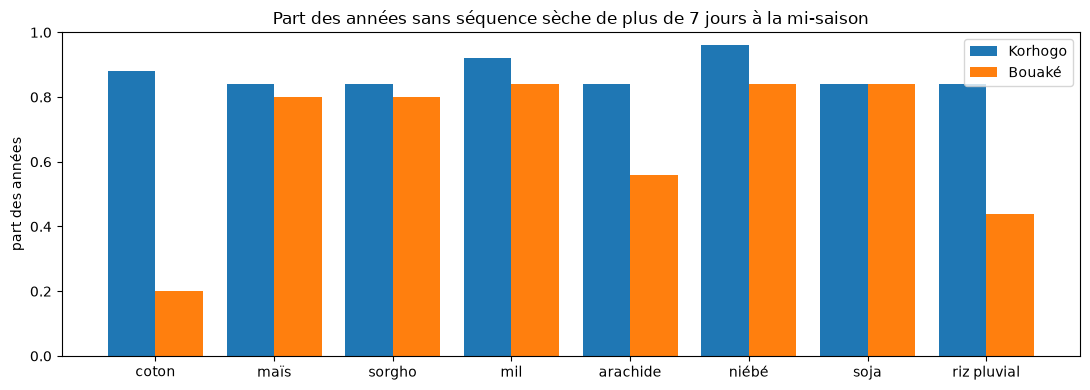

In [3]:
parts = {i: parts_par_culture(c["reference"]) for i, c in contextes.items()}
display(pd.concat({noms[i]: p for i, p in parts.items()}, axis=1))

figure, axe = plt.subplots(figsize=(11, 4))
largeur = 0.4
for decalage, couleur, (identifiant, p) in zip([-largeur / 2, largeur / 2], ["C0", "C1"], parts.items()):
    axe.bar([k + decalage for k in range(len(p))], p["sans_secheresse_mi_saison"], width=largeur, color=couleur,
            label=noms[identifiant])
axe.set(title="Part des années sans séquence sèche de plus de 7 jours à la mi-saison", ylabel="part des années",
        ylim=(0, 1), xticks=range(len(parts["korhogo"])), xticklabels=parts["korhogo"].index)
axe.legend()
plt.tight_layout()
plt.show()

**Constat.** À Bouaké, le coton passe sans séquence sèche de plus de 7 jours à sa mi-saison 0,2 des années seulement, avec une séquence médiane de 10 jours, alors que le maïs, le sorgho, le mil et le niébé atteignent au moins 0,8. À Korhogo, toutes les cultures sont entre 0,84 et 0,96. La couverture du besoin sur le cycle est en revanche élevée dans les deux villes, sauf pour le soja et le riz pluvial.

**Analyse.** La mi-saison du coton, du 81e au 140e jour après un début des pluies vers la mi-mars à Bouaké, tombe sur le creux de juillet que montre la phase 2. C'est un signal propre au lieu, tiré des séries IMERG, et non un effet de la composition des rotations. Il suppose cependant que chaque culture est semée au début des pluies. Un coton semé plus tard à Bouaké, ce qui reste à confirmer localement, ne subirait pas ce creux de la même façon.

**Décision.** Le résultat est gardé, et l'hypothèse de semis au début des pluies est écrite dans les limites.

## 3. Évaluations détaillées des stratégies, scénario de référence

Les colonnes bas et haut donnent, pour l'eau, l'intervalle à 90 % obtenu en rééchantillonnant les années, graine fixée.

In [4]:
for identifiant, contexte in contextes.items():
    print(noms[identifiant])
    display(tableau_evaluations(STRATEGIES, contexte["reference"]))

Korhogo


,strategie,critere,indicateur,valeur,bas,haut,unite,score,niveau,source
0,coton_mais,eau,couverture_du_besoin,0.980,0.940,1.000,part des années,4.900,calcule,"FAO56_T11_T12, IMERG, POWER"
1,coton_mais,eau,secheresse_mi_saison,0.860,0.740,0.960,part des années,4.300,calcule,"FAO56_C5_C8, FAO56_T11_T12, IMERG"
2,coton_mais,revenu,acces_debouche_organise,0.500,NaN,NaN,part des années,2.500,hypothese,ZAGBAI2006
3,coton_mais,sol,apport_azote_legumineuses,0.000,NaN,NaN,part des années,0.000,hypothese,YUSUF2009
4,coton_niebe_mais,eau,couverture_du_besoin,0.960,0.907,1.000,part des années,4.800,calcule,"FAO56_T11_T12, IMERG, POWER"
5,coton_niebe_mais,eau,secheresse_mi_saison,0.893,0.800,0.973,part des années,4.467,calcule,"FAO56_C5_C8, FAO56_T11_T12, IMERG"
6,coton_niebe_mais,revenu,acces_debouche_organise,0.333,NaN,NaN,part des années,1.667,hypothese,ZAGBAI2006
7,coton_niebe_mais,sol,apport_azote_legumineuses,0.333,NaN,NaN,part des années,1.667,hypothese,YUSUF2009
8,sorgho_niebe,eau,couverture_du_besoin,0.960,0.920,1.000,part des années,4.800,calcule,"FAO56_T11_T12, IMERG, POWER"
9,sorgho_niebe,eau,secheresse_mi_saison,0.900,0.820,0.980,part des années,4.500,calcule,"FAO56_C5_C8, FAO56_T11_T12, IMERG"


Bouaké


,strategie,critere,indicateur,valeur,bas,haut,unite,score,niveau,source
0,coton_mais,eau,couverture_du_besoin,0.920,0.840,0.980,part des années,4.600,calcule,"FAO56_T11_T12, IMERG, POWER"
1,coton_mais,eau,secheresse_mi_saison,0.500,0.400,0.600,part des années,2.500,calcule,"FAO56_C5_C8, FAO56_T11_T12, IMERG"
2,coton_mais,revenu,acces_debouche_organise,0.500,NaN,NaN,part des années,2.500,hypothese,ZAGBAI2006
3,coton_mais,sol,apport_azote_legumineuses,0.000,NaN,NaN,part des années,0.000,hypothese,YUSUF2009
4,coton_niebe_mais,eau,couverture_du_besoin,0.907,0.813,0.973,part des années,4.533,calcule,"FAO56_T11_T12, IMERG, POWER"
5,coton_niebe_mais,eau,secheresse_mi_saison,0.613,0.520,0.707,part des années,3.067,calcule,"FAO56_C5_C8, FAO56_T11_T12, IMERG"
6,coton_niebe_mais,revenu,acces_debouche_organise,0.333,NaN,NaN,part des années,1.667,hypothese,ZAGBAI2006
7,coton_niebe_mais,sol,apport_azote_legumineuses,0.333,NaN,NaN,part des années,1.667,hypothese,YUSUF2009
8,sorgho_niebe,eau,couverture_du_besoin,0.920,0.840,0.980,part des années,4.600,calcule,"FAO56_T11_T12, IMERG, POWER"
9,sorgho_niebe,eau,secheresse_mi_saison,0.820,0.700,0.920,part des années,4.100,calcule,"FAO56_C5_C8, FAO56_T11_T12, IMERG"


**Constat.** À Korhogo, la part des années sans séquence sèche à la mi-saison vaut 0,86 pour coton puis maïs, de 0,74 à 0,96, 0,893 pour coton, niébé puis maïs et 0,9 pour sorgho puis niébé, de 0,82 à 0,98. À Bouaké, elle vaut 0,5 pour coton puis maïs, de 0,4 à 0,6, 0,613 pour coton, niébé puis maïs et 0,82 pour sorgho puis niébé, de 0,7 à 0,92.

**Analyse.** À Korhogo, les intervalles des trois stratégies se recouvrent largement, et l'eau ne les distingue pas. À Bouaké, l'intervalle de sorgho puis niébé ne recoupe pas celui de coton puis maïs, et l'écart tient au coton.

**Décision.** L'outil montre ces intervalles avec chaque score d'eau, pour que l'écart entre stratégies ne soit pas lu au-delà de ce que les années permettent.

## 4. Scores et classement pour chaque priorité

Korhogo, priorité eau


,eau,revenu,sol,actuelle,note,rang
coton_niebe_mais,4.633,1.667,1.667,False,3.447,1
sorgho_niebe,4.650,0.000,2.500,False,3.290,2
coton_mais,4.600,2.500,0.000,True,3.260,3


Korhogo, priorité revenu


,eau,revenu,sol,actuelle,note,rang
coton_mais,4.600,2.500,0.000,True,2.42,1
coton_niebe_mais,4.633,1.667,1.667,False,2.26,2
sorgho_niebe,4.650,0.000,2.500,False,1.43,3


Korhogo, priorité sol


,eau,revenu,sol,actuelle,note,rang
sorgho_niebe,4.650,0.000,2.500,False,2.43,1
coton_niebe_mais,4.633,1.667,1.667,False,2.26,2
coton_mais,4.600,2.500,0.000,True,1.42,3


... (2 outputs left out)

Bouaké, priorité revenu


,eau,revenu,sol,actuelle,note,rang
coton_mais,3.55,2.500,0.000,True,2.210,1
coton_niebe_mais,3.80,1.667,1.667,False,2.093,2
sorgho_niebe,4.35,0.000,2.500,False,1.370,3


Bouaké, priorité sol


,eau,revenu,sol,actuelle,note,rang
sorgho_niebe,4.35,0.000,2.500,False,2.370,1
coton_niebe_mais,3.80,1.667,1.667,False,2.093,2
coton_mais,3.55,2.500,0.000,True,1.210,3


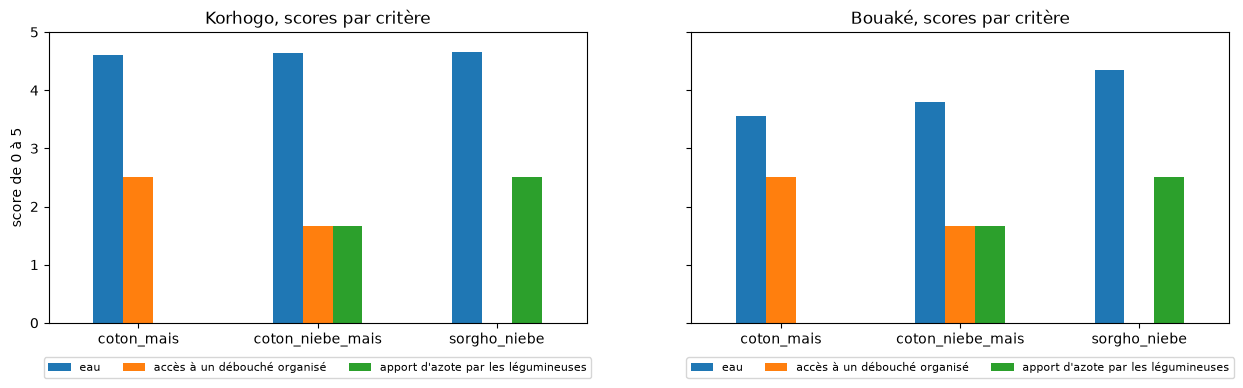

In [5]:
for identifiant, contexte in contextes.items():
    for priorite, poids in POIDS_PAR_PRIORITE.items():
        print(f"{noms[identifiant]}, priorité {priorite}")
        display(tableau_scores(STRATEGIES, contexte["reference"], poids))

figure, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for axe, (identifiant, contexte) in zip(axes, contextes.items()):
    table = tableau_scores(STRATEGIES, contexte["reference"], POIDS_PAR_PRIORITE["eau"]).sort_index()
    table[list(CRITERES)].rename(columns=LIBELLES).plot.bar(ax=axe, rot=0)
    axe.set(title=f"{noms[identifiant]}, scores par critère", ylabel="score de 0 à 5", ylim=(0, 5))
    axe.legend(fontsize=8, loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()

**Constat.** Pour la priorité eau, Bouaké classe sorgho puis niébé premier, note 3,11, devant coton, niébé puis maïs, 2,947, et coton puis maïs, 2,63. Korhogo classe coton, niébé puis maïs premier, note 3,447, devant sorgho puis niébé, 3,29, et coton puis maïs, 3,26. Pour les priorités débouché et azote, les deux villes reçoivent le même classement, coton puis maïs premier pour le débouché, sorgho puis niébé premier pour l'azote.

**Analyse.** Korhogo et Bouaké se distinguent désormais sur la priorité eau, et l'écart vient des séquences sèches de mi-saison observées par IMERG. À Korhogo, en revanche, les scores d'eau des trois stratégies ne vont que de 4,6 à 4,65, si bien que leur ordre y est fixé par l'azote et le débouché. Pour les deux autres priorités, l'identité des classements est attendue, puisque ces critères pèsent 0,6 et ne dépendent pas du lieu.

**Décision.** Ce résultat est rapporté tel quel, sans forcer l'écart entre villes.

## 5. Sensibilité à une pluie réduite et à un début de saison retardé

Dans le scénario de pluie réduite, toute la pluie est multipliée par 0,8, début de saison compris. Dans le scénario de début retardé, chaque cycle commence 14 jours après le début de saison de l'année.

In [6]:
for identifiant, contexte in contextes.items():
    print(noms[identifiant])
    valeurs = tableau_scenarios(STRATEGIES, contexte)
    display(valeurs.loc[valeurs.index.get_level_values("indicateur").isin(["couverture_du_besoin", "secheresse_mi_saison"])])
    for priorite, poids in POIDS_PAR_PRIORITE.items():
        rangs, stable, changeants = sensibilite(STRATEGIES, contexte, poids)
        print(f"priorité {priorite}, classement stable {stable}, scénarios qui le changent {changeants}")
        display(rangs)

Korhogo


reference  pluie_moins_20_pourcent  \
strategie        indicateur                                                 
coton_mais       couverture_du_besoin      0.980                    0.740   
                 secheresse_mi_saison      0.860                    0.860   
coton_niebe_mais couverture_du_besoin      0.960                    0.707   
                 secheresse_mi_saison      0.893                    0.867   
sorgho_niebe     couverture_du_besoin      0.960                    0.780   
                 secheresse_mi_saison      0.900                    0.880   

                                       debut_retarde_de_14_jours  
strategie        indicateur                                       
coton_mais       couverture_du_besoin                      1.000  
                 secheresse_mi_saison                      0.900  
coton_niebe_mais couverture_du_besoin                      1.000  
                 secheresse_mi_saison                      0.893  
sorgho_niebe     couverture_du_besoin                      1.000  
                 secheresse_mi_saison                      0.880

priorité eau, classement stable False, scénarios qui le changent ['debut_retarde_de_14_jours']


,reference,pluie_moins_20_pourcent,debut_retarde_de_14_jours
coton_niebe_mais,1,1,1
sorgho_niebe,2,2,3
coton_mais,3,3,2


priorité revenu, classement stable True, scénarios qui le changent []


,reference,pluie_moins_20_pourcent,debut_retarde_de_14_jours
coton_mais,1,1,1
coton_niebe_mais,2,2,2
sorgho_niebe,3,3,3


... (6 outputs left out)

priorité revenu, classement stable True, scénarios qui le changent []


,reference,pluie_moins_20_pourcent,debut_retarde_de_14_jours
coton_mais,1,1,1
coton_niebe_mais,2,2,2
sorgho_niebe,3,3,3


priorité sol, classement stable True, scénarios qui le changent []


,reference,pluie_moins_20_pourcent,debut_retarde_de_14_jours
sorgho_niebe,1,1,1
coton_niebe_mais,2,2,2
coton_mais,3,3,3


**Constat.** À Bouaké, le classement ne change dans aucun scénario, pour aucune priorité. À Korhogo, pour la priorité eau, un début retardé de 14 jours intervertit sorgho puis niébé et coton puis maïs, dont les notes ne diffèrent que de 0,03 en référence. Les autres classements de Korhogo sont stables.

**Analyse.** L'instabilité de Korhogo porte sur deux stratégies que l'eau ne départage pas, et reflète leur quasi-égalité plus qu'un risque climatique. À Bouaké, l'avantage de sorgho puis niébé sur la priorité eau résiste aux deux scénarios.

**Décision.** L'outil déclare le classement de Korhogo instable pour la priorité eau et nomme le scénario du début retardé, comme le demande le critère 4 du cadrage.

## 6. Date de semis du coton

Le modèle sème chaque culture au début des pluies. Une enquête du CNRA auprès des producteurs de la variété Gouassou FUS1 relève que 70 % d'entre eux sèment le coton entre le 1er et le 30 juin au nord du 9e parallèle, où est Korhogo, et 80 % entre le 11 juin et le 10 juillet au sud, où est Bouaké, Gnapi et collègues, 2025, page 1575. Le coton est ici semé au début, au milieu ou à la fin de cette fenêtre, ou au début des pluies s'il survient plus tard, les autres cultures restant semées au début des pluies.

In [7]:
display(pd.DataFrame(FENETRE_SEMIS_COTON, index=["début de fenêtre", "fin de fenêtre"]))
for identifiant in LIEUX:
    semis = {"debut_des_pluies": contextes[identifiant]}
    for position in ["debut", "milieu", "fin"]:
        semis[f"coton_{position}_fenetre"] = contextes_du_lieu(identifiant, semis_coton(identifiant, position))
    rangs, coton = comparer_semis(STRATEGIES, semis)
    print(noms[identifiant])
    display(coton)
    display(rangs)

,korhogo,bouake
début de fenêtre,06-01,06-11
fin de fenêtre,06-30,07-10


Korhogo


,debut_des_pluies,coton_debut_fenetre,coton_milieu_fenetre,coton_fin_fenetre
annees,25.00,25.00,25.00,24.000
couverture_du_besoin,1.00,0.92,0.76,0.708
sans_secheresse_mi_saison,0.88,1.00,0.68,0.083
sequence_seche_mi_saison_mediane_jours,5.00,4.00,6.00,12.000


eau                                         \
                 coton_debut_fenetre coton_fin_fenetre coton_milieu_fenetre   
coton_mais                         2                 3                    3   
coton_niebe_mais                   1                 2                    2   
sorgho_niebe                       2                 1                    1   

                                               revenu                    \
                 debut_des_pluies coton_debut_fenetre coton_fin_fenetre   
coton_mais                      3                   1                 1   
coton_niebe_mais                1                   2                 2   
sorgho_niebe                    2                   3                 3   

                                                                       sol  \
                 coton_milieu_fenetre debut_des_pluies coton_debut_fenetre   
coton_mais                          1                1                   3   
coton_niebe_mais                    2                2                   2   
sorgho_niebe                        3                3                   1   

                                                                          
                 coton_fin_fenetre coton_milieu_fenetre debut_des_pluies  
coton_mais                       3                    3                3  
coton_niebe_mais                 2                    2                2  
sorgho_niebe                     1                    1                1

Bouaké


,debut_des_pluies,coton_debut_fenetre,coton_milieu_fenetre,coton_fin_fenetre
annees,25.00,25.00,24.000,24.000
couverture_du_besoin,0.96,0.48,0.375,0.167
sans_secheresse_mi_saison,0.20,0.60,0.333,0.083
sequence_seche_mi_saison_mediane_jours,10.00,7.00,9.000,12.000


eau                                         \
                 coton_debut_fenetre coton_fin_fenetre coton_milieu_fenetre   
coton_mais                         3                 3                    3   
coton_niebe_mais                   2                 2                    2   
sorgho_niebe                       1                 1                    1   

                                               revenu                    \
                 debut_des_pluies coton_debut_fenetre coton_fin_fenetre   
coton_mais                      3                   1                 1   
coton_niebe_mais                2                   2                 2   
sorgho_niebe                    1                   3                 3   

                                                                       sol  \
                 coton_milieu_fenetre debut_des_pluies coton_debut_fenetre   
coton_mais                          1                1                   3   
coton_niebe_mais                    2                2                   2   
sorgho_niebe                        3                3                   1   

                                                                          
                 coton_fin_fenetre coton_milieu_fenetre debut_des_pluies  
coton_mais                       3                    3                3  
coton_niebe_mais                 2                    2                2  
sorgho_niebe                     1                    1                1

**Constat.** À Bouaké, le classement reste le même pour les trois priorités quelle que soit la date de semis du coton. La pluie couvre pourtant le besoin du coton 0,96 des années s'il est semé au début des pluies, 0,48 s'il est semé le 11 juin, 0,375 le 25 juin et 0,167 le 10 juillet. À Korhogo, le classement de la priorité eau change. Coton, niébé puis maïs est premier pour un semis au début des pluies ou le 1er juin, sorgho puis niébé l'est pour un semis le 15 ou le 30 juin.

**Analyse.** À Bouaké, un semis précoce expose la mi-saison du coton au creux de juillet, un semis tardif expose la fin de son cycle à la saison sèche, si bien que coton puis maïs reste dernier pour la priorité eau dans tous les cas. À Korhogo, l'écart entre stratégies est faible et la date de semis suffit à le renverser. La durée de 195 jours du coton, tirée d'une ligne de FAO-56 établie pour l'Égypte, le Pakistan et la Californie, mène un cycle semé fin juin jusqu'en janvier, probablement au-delà des variétés ivoiriennes, ce qui exagère sans doute le manque d'eau du coton semé tard.

**Décision.** Le classement de Bouaké est déclaré indépendant de la date de semis du coton dans cette fenêtre. Celui de Korhogo en dépend pour la priorité eau, ce qu'écrivent les limites. Retenir le semis observé par le CNRA comme référence pour le coton reste une décision de l'équipe.

## 7. Critères à venir

**Constat.** Les extractions AppEEARS de MCD12Q1 sont soumises, et MOD13Q1, SMAP et SRTM suivront sur les points cultivés.

**Analyse.** L'humidité du sol au début de saison mesurée par SMAP et les périodes de sol nu tirées du NDVI de MODIS donneraient des indicateurs propres à chaque lieu et à chaque année.

**Décision.** Chacun deviendra une fonction inscrite dans `INDICATEURS`, alimentée par le champ `surfaces` du contexte, et ce notebook sera réexécuté.